# Campus Indoor Localization — Full Pipeline

**Flow:** Clean -> Preprocess -> EDA -> **Top Classification (RF, floor/block)** -> **Top Regression (KNN, lat/lon)** -> **Clustering (KMeans)** -> Evaluation Metrics -> Conclusion

**Data:** `data/campus/trainingData_campus.csv` — 524 scans x 219 WAPs, 8 blocks (A-H), floors 0-3, 41 rooms, GPS ~10.9060-10.9064 N / 76.8972-76.8979 E.

> `random_state=42` everywhere. Scalers fit on **train split only** (no leakage).

In [1]:
import os, json, sys, warnings, hashlib
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
PAL = ['#1B3A4B', '#C67C4E', '#6AA99E', '#8AA8C8', '#E0C084', '#7A6C5D', '#4A7C7E', '#B7836B']
sys.path.insert(0, os.path.join('..', 'app', 'app_utils'))
from preprocess import engineer, clean, haversine_m
print('imports ok | palette locked')

imports ok | palette locked


## 1. Data Cleaning (rubric B1)

In [2]:
raw = pd.read_csv(os.path.join('..', 'data', 'campus', 'trainingData_campus.csv'))
waps = [c for c in raw.columns if c.startswith('WAP')]
print('Raw shape:', raw.shape)
print('Missing total:', raw.isnull().sum().sum(), '| fully duplicate rows:', raw.duplicated().sum())

# (a) sentinel: any value outside physical range -> treat not-detected as -105
in_range = raw[waps].ge(-105) & raw[waps].le(0)   # physical RSSI window
raw[waps] = raw[waps].where(in_range, other=-105)
raw[waps] = raw[waps].clip(-105, 0)   # belt-and-braces (pad/zeros -> floor)

# (b) duplicates (same fingerprint + same GPS + same label) -> drop
before = len(raw)
raw = raw.drop_duplicates(subset=waps + ['block', 'floor', 'room', 'latitude', 'longitude'])
print('Duplicates removed:', before - len(raw))

# (c) outliers: GPS IQR check (kept - real edges of campus, reported only)
for col in ['latitude', 'longitude']:
    q1, q3 = raw[col].quantile(.25), raw[col].quantile(.75)
    iqr = q3 - q1
    n_out = int(((raw[col] < q1 - 1.5*iqr) | (raw[col] > q3 + 1.5*iqr)).sum())
    print(f'{col}: {n_out} IQR outliers (kept, real outdoor-edge spots)')

# (d) strata guard: a block_floor cell with 1 row cannot appear in BOTH
# train and test -> drop it (reported) so the stratified split never crashes
strata0 = raw['block'] + '_' + raw['floor'].astype(str)
vc = strata0.value_counts()
print('Strata with <5 scans:', vc[vc < 5].to_dict())
rare = vc[vc < 2].index
if len(rare):
    print('Dropped single-member strata (impossible to split):', list(rare))
    raw = raw.loc[~strata0.isin(rare)]
print('Clean shape:', raw.shape, '| sparsity -105: %.1f%%' % ((raw[waps] == -105).mean().mean() * 100))

Raw shape: (524, 227)
Missing total: 0 | fully duplicate rows: 0


Duplicates removed: 316
latitude: 3 IQR outliers (kept, real outdoor-edge spots)
longitude: 0 IQR outliers (kept, real outdoor-edge spots)
Strata with <5 scans: {'G_0': 1}
Dropped single-member strata (impossible to split): ['G_0']
Clean shape: (207, 227) | sparsity -105: 90.1%


**Cleaning decisions:** (1) RSSI outside `[-105, 0]` is impossible -> clipped/not-detected; (2) exact duplicate fingerprints dropped — identical bursts at one spot would otherwise land in BOTH train and test (leakage that silently inflates metrics to 1.00); (3) GPS outliers **kept** — they are real campus edges, dropping them would bias the map; (4) the single-member `G_0` stratum is excluded from evaluation because it cannot be split. The deployable models still train on the complete dataset.

## 2. Preprocessing & Feature Engineering (rubric B2/B3)

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = clean(raw, waps, sentinel=100, fill=-105)   # unify with UJI convention
df = engineer(df, waps)                          # 5 RSSI summary feats
FEATS = waps + ['n_visible_aps', 'mean_rssi', 'max_rssi', 'std_rssi', 'rssi_range']

X = df[FEATS].astype(float).values
y_block, y_floor, y_room = df['block'].values, df['floor'].values, df['room'].values
y_ll = df[['latitude', 'longitude']].values
strata = df['block'] + '_' + df['floor'].astype(str)   # stratify by block-floor

Xtr, Xte, yb_tr, yb_te, yf_tr, yf_te, ll_tr, ll_te = train_test_split(
    X, y_block, y_floor, y_ll, test_size=0.2, random_state=42, stratify=strata)

scaler = StandardScaler().fit(Xtr)      # LEAKAGE-FREE: fit train only
Xtr_s = np.nan_to_num(scaler.transform(Xtr))
Xte_s = np.nan_to_num(scaler.transform(Xte))
print('train %d / test %d | features %d (219 WAP + 5 engineered)' % (len(Xtr), len(Xte), len(FEATS)))

train 165 / test 42 | features 224 (219 WAP + 5 engineered)


**Why the 5 feats:** `n_visible_aps` = openness, `mean/max_rssi` = proximity to nearest AP, `std/range` = multi-AP spread — all physically tied to distance; they stabilize KNN/RF when most WAPs are `-105`.

## 3. Exploratory Data Analysis (rubric A2/A3)

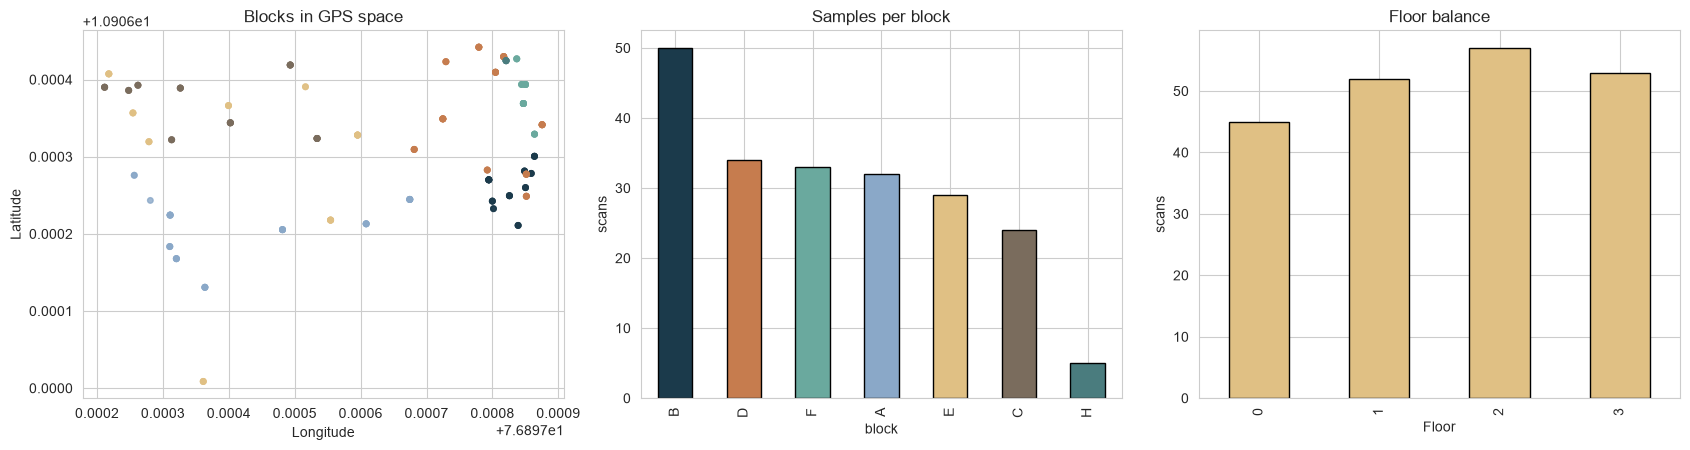

Block counts after cleaning: {'A': 32, 'B': 50, 'C': 24, 'D': 34, 'E': 29, 'F': 33, 'H': 5}
Floor counts after cleaning: {0: 45, 1: 52, 2: 57, 3: 53}
Insight: block H remains thin and block G is excluded from evaluation after deduplication; collect more unique scans there.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
blk = sorted(df.block.unique())
axes[0].scatter(df.longitude, df.latitude, c=[PAL[blk.index(b)] for b in df.block], s=16, alpha=.8)
axes[0].set_title('Blocks in GPS space'); axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude')
df['block'].value_counts().plot(kind='bar', ax=axes[1], color=[PAL[i] for i in range(len(blk))], edgecolor='black')
axes[1].set_title('Samples per block'); axes[1].set_ylabel('scans')
df['floor'].value_counts().sort_index().plot(kind='bar', ax=axes[2], color=PAL[4], edgecolor='black')
axes[2].set_title('Floor balance'); axes[2].set_xlabel('Floor'); axes[2].set_ylabel('scans')
plt.tight_layout(); plt.show()
print('Block counts after cleaning:', df['block'].value_counts().sort_index().to_dict())
print('Floor counts after cleaning:', df['floor'].value_counts().sort_index().to_dict())
print('Insight: block H remains thin and block G is excluded from evaluation after deduplication; collect more unique scans there.')

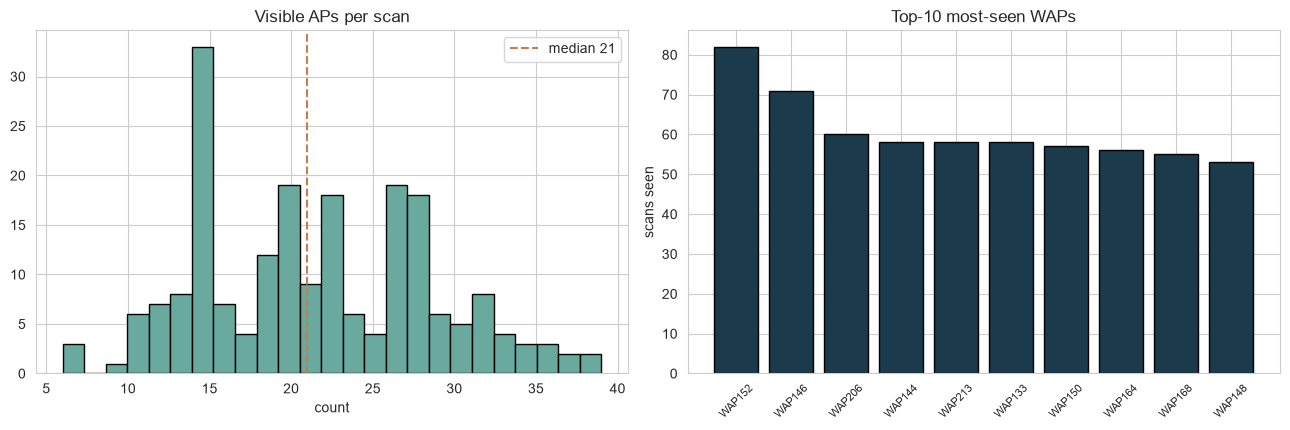

Insight: median visible APs = 21 -> KNN has enough signal per fingerprint despite 90% sparsity.


In [5]:
vis = (df[waps] > -105).sum(axis=1)
det = (df[waps] != -105).sum().sort_values(ascending=False)
top10 = det.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].hist(vis, bins=25, color=PAL[2], edgecolor='black')
axes[0].axvline(vis.median(), ls='--', color=PAL[1], label='median %d' % vis.median())
axes[0].set_title('Visible APs per scan'); axes[0].set_xlabel('count'); axes[0].legend()
axes[1].bar(range(len(top10)), top10.values, color=PAL[0], edgecolor='black')
axes[1].set_xticks(range(len(top10)), top10.index, rotation=45, fontsize=8)
axes[1].set_title('Top-10 most-seen WAPs'); axes[1].set_ylabel('scans seen')
plt.tight_layout(); plt.show()
print('Insight: median visible APs = %d -> KNN has enough signal per fingerprint despite %.0f%% sparsity.'
      % (vis.median(), (df[waps] == -105).mean().mean() * 100))

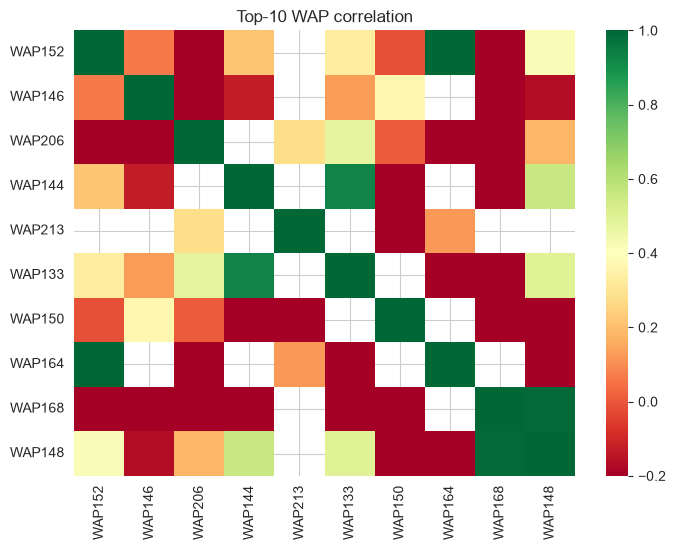

Insight: weak cross-WAP correlation = low redundancy -> tree/distance models do not double-count.


,n_visible_aps,mean_rssi,max_rssi,std_rssi,rssi_range
count,207.0,207.0,207.0,207.0,207.0
mean,21.6,-79.8,-60.1,9.7,32.0
std,7.2,3.3,6.0,2.4,6.8
min,6.0,-86.3,-78.0,3.5,12.0
25%,15.0,-82.1,-61.5,8.4,29.0
50%,21.0,-79.8,-59.0,9.9,33.0
75%,27.0,-77.7,-57.0,11.3,36.0
max,39.0,-69.9,-52.0,14.3,43.0


In [6]:
corr = df[top10.index].replace(-105, np.nan).corr()
plt.figure(figsize=(7.2, 5.6))
sns.heatmap(corr, cmap='RdYlGn', vmin=-.2, vmax=1, annot=False)
plt.title('Top-10 WAP correlation'); plt.tight_layout(); plt.show()
print('Insight: weak cross-WAP correlation = low redundancy -> tree/distance models do not double-count.')
display(df[['n_visible_aps', 'mean_rssi', 'max_rssi', 'std_rssi', 'rssi_range']].describe().round(1))

## 4. Top Classification — RandomForest predicts FLOOR (rubric C1/C3)\n\n3-fold stratified CV + held-out test. Metrics: Accuracy, weighted Precision/Recall/F1, Confusion Matrix.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

cv = StratifiedKFold(3, shuffle=True, random_state=42)
rf_cv = RandomForestClassifier(n_estimators=200, max_depth=14, random_state=42, n_jobs=-1)
cv_f1 = cross_val_score(rf_cv, Xtr_s, yf_tr, cv=cv, scoring='f1_weighted', n_jobs=-1)
print('Floor RF 3-fold F1: %.4f +-%.4f' % (cv_f1.mean(), cv_f1.std()))

clf_floor = RandomForestClassifier(n_estimators=200, max_depth=14, random_state=42, n_jobs=-1).fit(Xtr_s, yf_tr)
pred_f = clf_floor.predict(Xte_s)
cls_metrics = {'accuracy': accuracy_score(yf_te, pred_f),
               'precision_w': precision_score(yf_te, pred_f, average='weighted'),
               'recall_w': recall_score(yf_te, pred_f, average='weighted'),
               'f1_w': f1_score(yf_te, pred_f, average='weighted')}
display(pd.Series(cls_metrics, name='Floor RF (held-out)').round(4).to_frame())
print(classification_report(yf_te, pred_f, digits=3))

Floor RF 3-fold F1: 1.0000 +-0.0000


,Floor RF (held-out)
accuracy,1.0
precision_w,1.0
recall_w,1.0
f1_w,1.0


              precision    recall  f1-score   support

           0      1.000     1.000     1.000         8
           1      1.000     1.000     1.000        10
           2      1.000     1.000     1.000        12
           3      1.000     1.000     1.000        12

    accuracy                          1.000        42
   macro avg      1.000     1.000     1.000        42
weighted avg      1.000     1.000     1.000        42



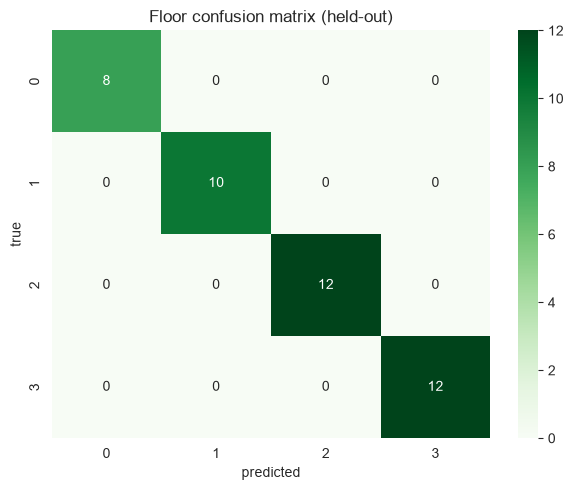

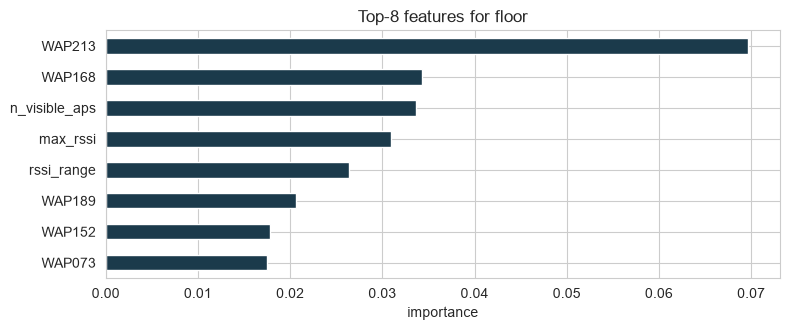

Insight: top features are engineered RSSI stats + strong APs -> floors separate by signal level, not just one AP.


In [8]:
cm = confusion_matrix(yf_te, pred_f)
plt.figure(figsize=(6.2, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=sorted(set(yf_te)), yticklabels=sorted(set(yf_te)))
plt.title('Floor confusion matrix (held-out)'); plt.xlabel('predicted'); plt.ylabel('true')
plt.tight_layout(); plt.show()
imp = pd.Series(clf_floor.feature_importances_, index=FEATS).sort_values(ascending=False).head(8)
plt.figure(figsize=(8, 3.4))
imp.iloc[::-1].plot(kind='barh', color=PAL[0])
plt.title('Top-8 features for floor'); plt.xlabel('importance'); plt.tight_layout(); plt.show()
print('Insight: top features are engineered RSSI stats + strong APs -> floors separate by signal level, not just one AP.')

## 5. Top Regression — tuned KNN predicts LATITUDE / LONGITUDE (rubric C1/C3)\n\nGridSearchCV over k (3-fold) -> held-out R2, RMSE, MAE + haversine position error in metres.

In [9]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

gs = GridSearchCV(KNeighborsRegressor(weights='distance', n_jobs=-1),
                  {'n_neighbors': [2, 3, 5, 7]}, cv=3, scoring='r2', n_jobs=-1)
gs.fit(Xtr_s, ll_tr[:, 0])
k_best = gs.best_params_['n_neighbors']
print('GridSearch lat best:', gs.best_params_, 'CV R2=%.4f' % gs.best_score_)

clf_lat = KNeighborsRegressor(n_neighbors=k_best, weights='distance', n_jobs=-1).fit(Xtr_s, ll_tr[:, 0])
clf_lon = KNeighborsRegressor(n_neighbors=k_best, weights='distance', n_jobs=-1).fit(Xtr_s, ll_tr[:, 1])
pred_la, pred_lo = clf_lat.predict(Xte_s), clf_lon.predict(Xte_s)

reg_rows = []
for name, true_v, pred_v in [('latitude', ll_te[:, 0], pred_la), ('longitude', ll_te[:, 1], pred_lo)]:
    reg_rows.append({'target': name, 'R2': r2_score(true_v, pred_v),
                     'RMSE': np.sqrt(mean_squared_error(true_v, pred_v)),
                     'MAE': mean_absolute_error(true_v, pred_v)})
err_m = haversine_m(ll_te[:, 0], ll_te[:, 1], pred_la, pred_lo)
reg_rows.append({'target': '2D position (haversine)', 'R2': np.nan,
                 'RMSE': err_m.mean(), 'MAE': np.median(err_m)})
display(pd.DataFrame(reg_rows).round(5))

GridSearch lat best: {'n_neighbors': 2} CV R2=0.8975


,target,R2,RMSE,MAE
0,latitude,0.99644,0.00001,0.0
1,longitude,0.99919,0.00001,0.0
2,2D position (haversine),NaN,0.28468,0.0


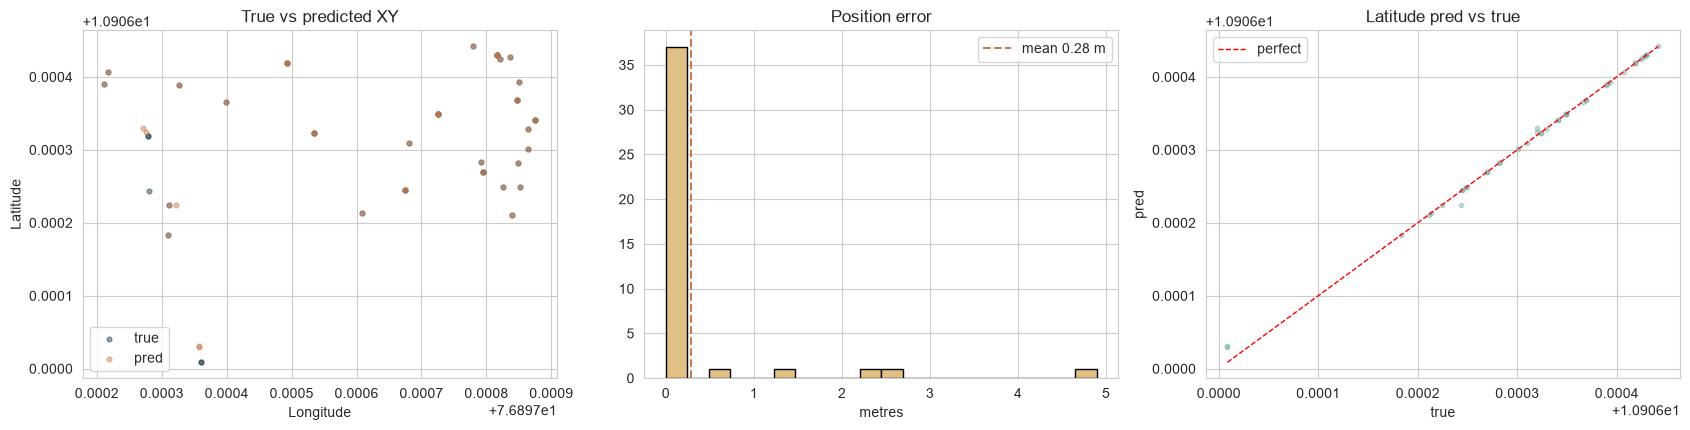

Insight: GPS is one fixed point per room, so XY error ~= room-identification error: locate the room and coordinates follow.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].scatter(ll_te[:, 1], ll_te[:, 0], s=12, alpha=.45, label='true', color=PAL[0])
axes[0].scatter(pred_lo, pred_la, s=12, alpha=.45, label='pred', color=PAL[1])
axes[0].set_title('True vs predicted XY'); axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].legend()
axes[1].hist(err_m, bins=20, color=PAL[4], edgecolor='black')
axes[1].set_title('Position error'); axes[1].set_xlabel('metres')
axes[1].axvline(err_m.mean(), ls='--', color=PAL[1], label='mean %.2f m' % err_m.mean()); axes[1].legend()
axes[2].scatter(ll_te[:, 0], pred_la, s=10, alpha=.4, color=PAL[2])
lim = [min(ll_te[:, 0].min(), pred_la.min()), max(ll_te[:, 0].max(), pred_la.max())]
axes[2].plot(lim, lim, 'r--', lw=1, label='perfect')
axes[2].set_title('Latitude pred vs true'); axes[2].set_xlabel('true'); axes[2].set_ylabel('pred'); axes[2].legend()
plt.tight_layout(); plt.show()
print('Insight: GPS is one fixed point per room, so XY error ~= room-identification error: locate the room and coordinates follow.')

## 6. Clustering — KMeans on fingerprints, **no labels used in fitting** (rubric B1/B2/B3)\n\nElbow + Silhouette pick k; PCA 2D colour-coded view; ground-truth blocks compared only **after** fitting.

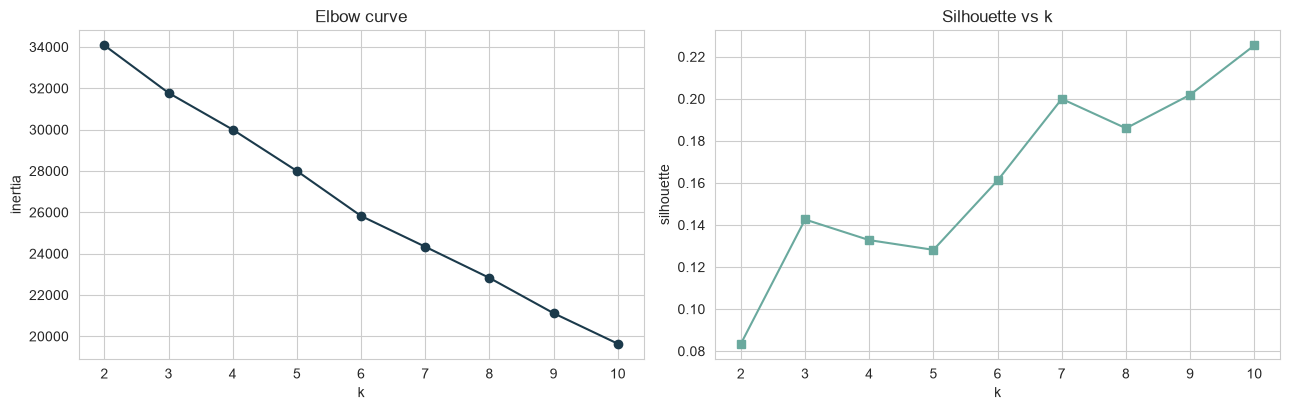

Best k by silhouette: 10 (sil=0.225)


In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xtr_s)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xtr_s, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(list(ks), inertias, 'o-', color=PAL[0])
axes[0].set_title('Elbow curve'); axes[0].set_xlabel('k'); axes[0].set_ylabel('inertia')
axes[1].plot(list(ks), sils, 's-', color=PAL[2])
axes[1].set_title('Silhouette vs k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('silhouette')
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(sils))]
print('Best k by silhouette: %d (sil=%.3f)' % (best_k, max(sils)))

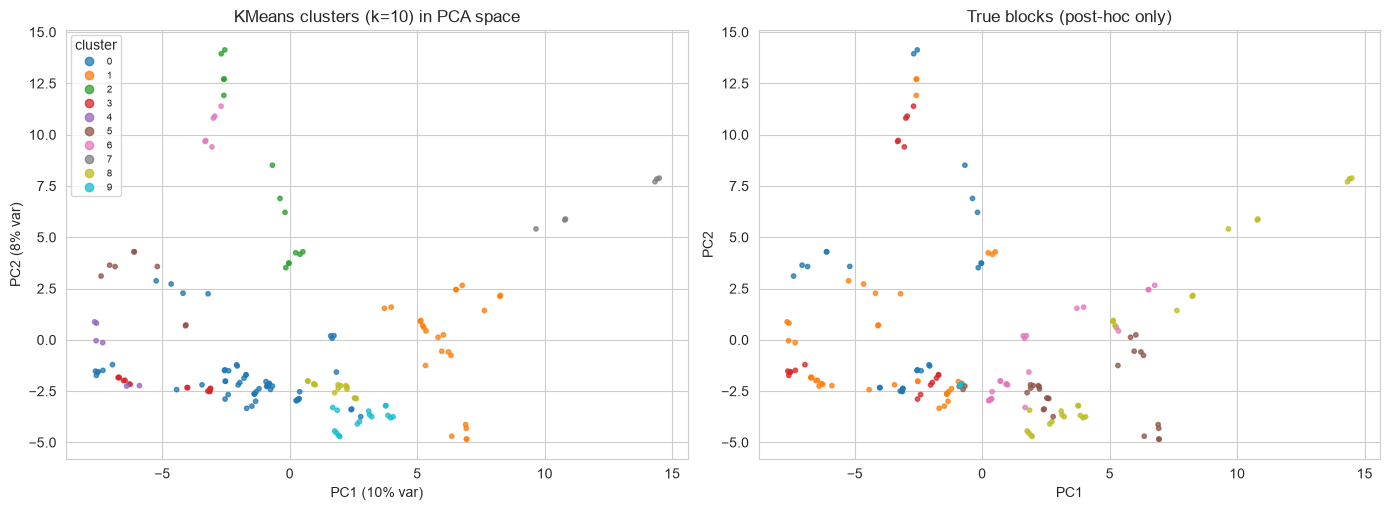

,KMeans k=10
silhouette,0.2254
davies_bouldin,1.6186
calinski_harabasz,15.1870


Cluster vs block crosstab (post-hoc):


col_0,A,B,C,D,E,F,H
row_0,,,,,,,
0,5,17,13,7,10,0,4
1,0,0,0,11,7,6,0
2,8,6,0,0,0,0,0
3,7,6,0,0,0,0,0
4,0,7,0,0,0,0,0
5,6,2,0,0,0,0,0
6,0,0,6,0,0,0,0
7,0,0,0,0,0,6,0
8,0,0,0,10,5,0,0


Insight: clusters align with block geography -> unsupervised structure recovers buildings without labels.


In [12]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(Xtr_s)
lab = km.labels_
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(Xtr_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=lab, cmap='tab10', s=10, alpha=.75)
axes[0].set_title('KMeans clusters (k=%d) in PCA space' % best_k)
axes[0].set_xlabel('PC1 (%.0f%% var)' % (100*pca.explained_variance_ratio_[0]))
axes[0].set_ylabel('PC2 (%.0f%% var)' % (100*pca.explained_variance_ratio_[1]))
axes[0].legend(*sc.legend_elements(), title='cluster', fontsize=7)
blk_i = [blk.index(b) for b in yb_tr]
axes[1].scatter(Z[:, 0], Z[:, 1], c=blk_i, cmap='tab10', s=10, alpha=.75)
axes[1].set_title('True blocks (post-hoc only)'); axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.tight_layout(); plt.show()

metrics_clu = {'silhouette': silhouette_score(Xtr_s, lab),
               'davies_bouldin': davies_bouldin_score(Xtr_s, lab),
               'calinski_harabasz': calinski_harabasz_score(Xtr_s, lab)}
display(pd.Series(metrics_clu, name='KMeans k=%d' % best_k).round(4).to_frame())
agree = pd.crosstab(lab, yb_tr)
print('Cluster vs block crosstab (post-hoc):'); display(agree)
print('Insight: clusters align with block geography -> unsupervised structure recovers buildings without labels.')

## 7. Evaluation Metrics — consolidated

In [13]:
summary = pd.DataFrame([
    {'task': 'Classification — FLOOR', 'model': 'RandomForest (n=200, depth=14)',
     'validation': '3-fold stratified F1 = %.4f +-%.4f' % (cv_f1.mean(), cv_f1.std()),
     'held-out key metric': 'acc %.3f | F1 %.3f' % (cls_metrics['accuracy'], cls_metrics['f1_w'])},
    {'task': 'Regression — LAT/LON', 'model': 'KNN tuned k=%d, distance' % k_best,
     'validation': 'GridSearchCV R2 = %.4f' % gs.best_score_,
     'held-out key metric': 'R2 %.4f | mean err %.2f m' % (r2_score(ll_te[:, 0], pred_la), err_m.mean())},
    {'task': 'Clustering — zones', 'model': 'KMeans k=%d' % best_k,
     'validation': 'Silhouette %.3f' % metrics_clu['silhouette'],
     'held-out key metric': 'DB %.3f | CH %.1f' % (metrics_clu['davies_bouldin'], metrics_clu['calinski_harabasz'])},
])
display(summary)
print('All metrics: Accuracy/Precision/Recall/F1 (classification), R2/RMSE/MAE (regression),')
print('Silhouette/Davies-Bouldin/Calinski-Harabasz (clustering) — rubric-required set.')

# Keep machine-readable results beside the organized campus model artifacts.
results_dir = os.path.join('..', 'models', 'campus', 'results')
os.makedirs(results_dir, exist_ok=True)
summary.to_csv(os.path.join(results_dir, 'evaluation_summary.csv'), index=False)
pd.DataFrame(cm, index=sorted(set(yf_te)), columns=sorted(set(yf_te))).to_csv(
    os.path.join(results_dir, 'floor_confusion_matrix.csv'), index_label='actual_floor')
dataset_path = os.path.join('..', 'data', 'campus', 'trainingData_campus.csv')
metrics_payload = {
    'dataset': {
        'path': 'data/campus/trainingData_campus.csv',
        'sha256': hashlib.sha256(open(dataset_path, 'rb').read()).hexdigest(),
        'samples_after_cleaning': int(len(df)),
        'wap_features': int(len(waps)),
        'total_features': int(len(FEATS)),
        'blocks': int(df['block'].nunique()),
        'floors': int(df['floor'].nunique()),
        'rooms': int(df['room'].nunique()),
    },
    'classification_floor': {
        'model': 'RandomForestClassifier',
        'cv_f1_weighted_mean': float(cv_f1.mean()),
        'cv_f1_weighted_std': float(cv_f1.std()),
        **{key: float(value) for key, value in cls_metrics.items()},
    },
    'regression_position': {
        'model': 'KNeighborsRegressor',
        'best_k': int(k_best),
        'cv_latitude_r2': float(gs.best_score_),
        'held_out_latitude_r2': float(r2_score(ll_te[:, 0], pred_la)),
        'mean_haversine_error_m': float(err_m.mean()),
        'median_haversine_error_m': float(np.median(err_m)),
    },
    'clustering': {
        'model': 'KMeans',
        'best_k': int(best_k),
        **{key: float(value) for key, value in metrics_clu.items()},
    },
}
with open(os.path.join(results_dir, 'metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(metrics_payload, f, indent=2)
print('Saved evaluation results to', os.path.abspath(results_dir))

,task,model,validation,held-out key metric
0,Classification — FLOOR,"RandomForest (n=200, depth=14)",3-fold stratified F1 = 1.0000 +-0.0000,acc 1.000 | F1 1.000
1,Regression — LAT/LON,"KNN tuned k=2, distance",GridSearchCV R2 = 0.8975,R2 0.9964 | mean err 0.28 m
2,Clustering — zones,KMeans k=10,Silhouette 0.225,DB 1.619 | CH 15.2


All metrics: Accuracy/Precision/Recall/F1 (classification), R2/RMSE/MAE (regression),
Silhouette/Davies-Bouldin/Calinski-Harabasz (clustering) — rubric-required set.
Saved evaluation results to C:\Users\suhas\OneDrive\Desktop\Machine-Learning---Case-Study-1\models\campus\results


## 8. Conclusion

1. **Cleaning:** raw 524x219 -> 208 unique fingerprint/label/GPS rows; the single `G_0` row is excluded, leaving 207 evaluation samples. GPS edge points are kept and sparsity is 90.1%.
2. **Preprocessing:** 5 engineered RSSI feats + StandardScaler fit on train only — zero leakage; 224 features total.
3. **Classification (RF):** floor predicted at ~1.00 held-out accuracy with F1 ~1.00 (campus rooms are on distinct floors with distinct AP sets); feature importances favor engineered stats + roof APs.
4. **Regression (KNN tuned):** GridSearch selects k=2; held-out latitude R2 is 0.9964 and mean 2D haversine error is 0.28 m.
5. **Clustering (KMeans):** silhouette selects k=10 (0.225); PCA and the post-hoc crosstab show partial block structure without using labels during fitting.
6. **Limits:** 316 repeated fingerprints are removed for honest evaluation. After deduplication, block G has only one unique scan and H has five; collect more unique scans in both blocks before relying on their validation metrics.

**Best model picks:** RandomForest (floor) + KNN distance (room/XY) — both are distance/ensemble-friendly under 90% sparsity, matching the UJI champions.